In [1]:
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

print("Qiskit version:", qiskit.__version__)
print("All libraries imported successfully!")

Qiskit version: 2.5.2
All libraries imported successfully!


## Circuit A: One X Gate

**Prediction before execution:** The qubit starts in state |0⟩. Applying one X gate flips it to |1⟩. Therefore, I predict that all 100 shots will produce measurement outcome `1`.

In [2]:
# Circuit A: One X gate

circuit_a = QuantumCircuit(1, 1)

circuit_a.x(0)
circuit_a.measure(0, 0)

print(circuit_a.draw(output="text"))

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [5]:
compiled_a = transpile(circuit_a, simulator)

result_a = simulator.run(
    compiled_a,
    shots=100
).result()

counts_a = result_a.get_counts()

print("Measurement results:", counts_a)
print("Total shots:", sum(counts_a.values()))

Measurement results: {'1': 100}
Total shots: 100


In [4]:
simulator = AerSimulator()

In [6]:
plot_histogram(counts_a, title="Circuit A: One X Gate")
plt.show()

{'1': 100}


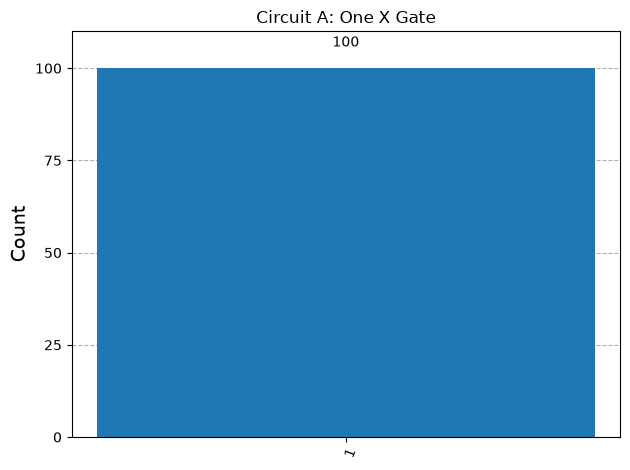

In [17]:
print(counts_a)

fig = plot_histogram(counts_a, title="Circuit A: One X Gate")
display(fig)

## Circuit B: Two X Gates

**Prediction before execution:** The qubit starts in state |0⟩. The first X gate flips it to |1⟩, and the second X gate flips it back to |0⟩. Therefore, I predict that all 100 shots will produce measurement outcome `0`.

In [7]:
# Circuit B: Two X gates

circuit_b = QuantumCircuit(1, 1)

circuit_b.x(0)
circuit_b.x(0)
circuit_b.measure(0, 0)

print(circuit_b.draw(output="text"))

     ┌───┐┌───┐┌─┐
  q: ┤ X ├┤ X ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 


In [8]:
compiled_b = transpile(circuit_b, simulator)

result_b = simulator.run(
    compiled_b,
    shots=100
).result()

counts_b = result_b.get_counts()

print("Measurement results:", counts_b)
print("Total shots:", sum(counts_b.values()))

Measurement results: {'0': 100}
Total shots: 100


In [15]:
plot_histogram(counts_b, title="Circuit B: Two X Gates")
plt.show()

Circuit B results: {'0': 100}


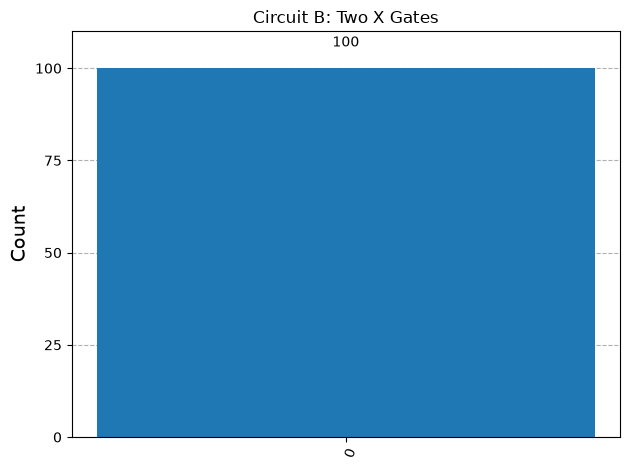

In [16]:
print("Circuit B results:", counts_b)

fig = plot_histogram(counts_b, title="Circuit B: Two X Gates")
display(fig)

## Circuit C: One H Gate

**Prediction before execution:** The qubit starts in state |0⟩. Applying an H gate creates an equal superposition of |0⟩ and |1⟩. Therefore, I predict that approximately 50 shots will produce `0` and 50 shots will produce `1`. The actual counts may vary.

In [18]:
# Circuit C: One H gate

circuit_c = QuantumCircuit(1, 1)

circuit_c.h(0)
circuit_c.measure(0, 0)

print(circuit_c.draw(output="text"))

     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


compiled_c = transpile(circuit_c, simulator)

result_c = simulator.run(
    compiled_c,
    shots=100
).result()

counts_c = result_c.get_counts()

print("Measurement results:", counts_c)
print("Total shots:", sum(counts_c.values()))

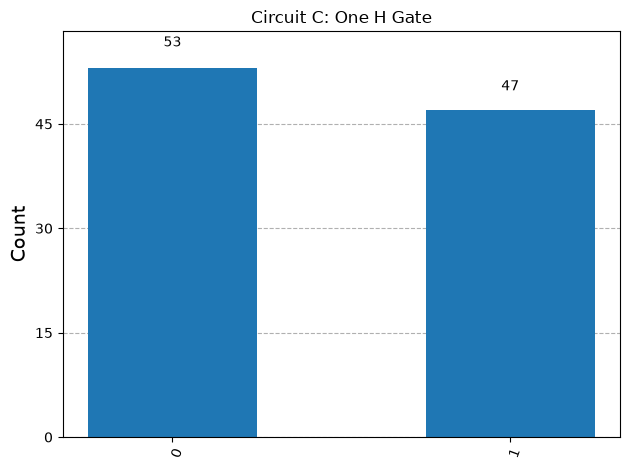

In [20]:
fig = plot_histogram(
    counts_c,
    title="Circuit C: One H Gate"
)
display(fig)

## Comparison of Predictions and Actual Results

| Circuit   | Gates Applied |        Predicted Outcome          |     Actual Result    |
|-----------|---------------|-----------------------------------|----------------------|
| Circuit A | One X gate    |            `1`                    |   `{'1': 100}`       |
| Circuit B | Two X gates   |            `0`                    |   `{'0': 100}`       |
| Circuit C | One H gate    | Approximately 50% `0` and 50% `1` | `{'0': 53, '1': 47}` |

### Analysis

**Circuit A:** The X gate flips the initial state from \(|0\rangle\) to \(|1\rangle\). All 100 shots produced `1`, matching the prediction.

**Circuit B:** Two consecutive X gates return the qubit to its initial state \(|0\rangle\). All 100 shots produced `0`, matching the prediction.

**Circuit C:** The H gate creates an equal superposition of \(|0\rangle\) and \(|1\rangle\). The simulation produced 53 measurements of `0` and 47 measurements of `1`. These results are close to the predicted equal distribution, although the counts are not exactly equal.

### Conclusion

This experiment demonstrated how X and H gates affect a single qubit. One X gate flips the state, two X gates cancel each other out, and an H gate creates a superposition with probabilistic measurement outcomes. The predictions were compared with the simulated measurement results using Qiskit.